# Black Scholes Model

### Import Libraries : Exhaustive list, not all being used

In [1]:
# data manipuation
import pandas as pd
import numpy as np

# panda technical analysis 
import pandas_ta as ta

# to reload another python script 
from importlib import reload

# data visualization
import matplotlib as mpl

import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (10,6)
plt.style.use('fivethirtyeight')

# statistical visual representation
import seaborn as sns

import cufflinks as cf                                                        # new package - cufflinks
cf.set_config_file(offline=True, theme='pearl',dimensions=((1000,600)))       # cf.set_config() -- (w,h)

import plotly.express as px
px.defaults.width, px.defaults.height = 1000,600

# statistical analysis & optimizatio
import scipy.stats as scs
import scipy.optimize as sco

# scikit learn(sklearn) package is used primarily for machine learning
import sklearn
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline

# Ignore warnings - optional
import warnings
warnings.filterwarnings('ignore')

# data retrival
import yfinance as yf

# float display
pd.options.display.float_format = '{:0.4f}'.format

# operating system
import os

# Image package
from PIL import Image

# table formation
from tabulate import tabulate

# datetime handling
from datetime import datetime

path_dir = 'C:/Admin/CQF Course/Python Labs/Black Scholes Option Pricing'

The Black Scholes model was published in 1973 for non-dividend paying stocks and since then the model has created a revolution in quantitative finance and opened up derivatives pricing paradigm. Black Scholes model is based on number of assumptions about how financial markets operate and those are:

- Arbitrage Free Markets
- Frictionless and Continuous Markets
-Risk Free Rates
- Log-normally Distributed Price Movements
- Constant Volatility

These assumptions maynot hold true in reality, but are not particularly limiting. The generalized Black Scholes framework have been extended to price derivaties of other asset classes such as Black 76 (Commodity Futures) and Garman-Kohlhagen (FX Futures) that are currently used in derivative pricing and risk management.

## Black Scholes Formula

The Black–Scholes equation describes the price of the option over time as

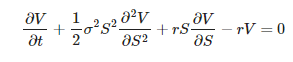

In [2]:
Image.open(os.path.join(path_dir, 'BSM_1.png'))

Solving the above equation, we know that the value of a call and  option for a non-dividend paying stock is:
- S - is the spot price of the underlying asset
- K is the strike price
- r is the annualized continuous compounded risk free rate
- σ is the volatility of returns of the underlying asset
- t is time to maturity (expressed in years)
- N(x) is the standard normal cumulative distribution

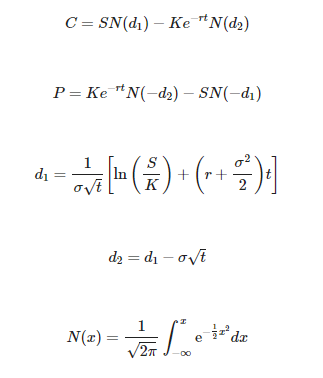

In [3]:
Image.open(os.path.join(path_dir, 'BSM_2.png'))

## Greeks

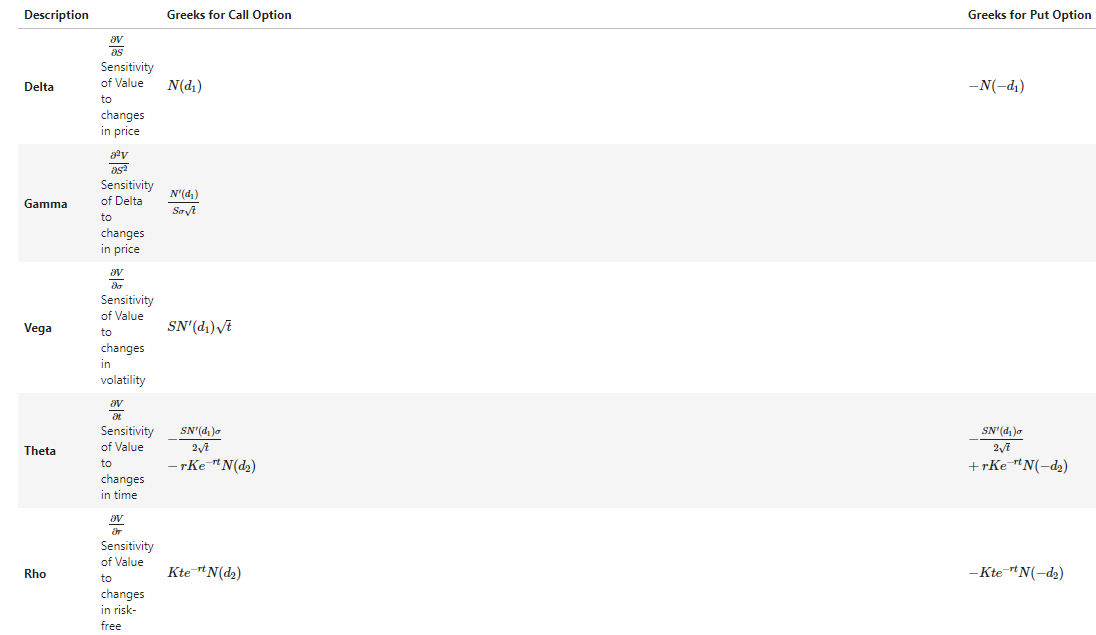

In [4]:
Image.open(os.path.join(path_dir, 'BSM_3.png'))

## Options Object

Python is an object oriented programming language. Almost everything in Python is an object, with its properties and methods. There are two common programming paradigm in Python.

- Procedural Programming
- Object-oriented Programming (OOP)

The key difference between them is that in OOP, objects are at the center, not only representing the data, as in the procedural programming, but in the overall structure of the program as well.

## Class

We use Classes to create user-defined data structures. Classes define functions called methods, which identify the characteristics and actions that an object created from the class can perform with its data. A Class is like an object constructor, or a "blueprint" for creating objects. To create a class, use the keyword class

**\_\_init\_\_** 

The properties of the class objects are defined in a method called \_\_init\_\_

-  \_\_init\_\_() sets the initial state of the object by assigning the values of the object’s properties.
- \_\_init\_\_() initializes each new instance of the class
- Attributes created in \_\_init\_\_() are called instance attributes, while class attributes are attributes that have the same value for all class instances.

**self**

The self is a parameter used to represent the instance of the class. With self, you can access the attributes and methods of the class in python. It binds the attributes with the given arguments. When a new class instance is created, the instance is automatically passed to the self parameter in __init__() so that new attributes can be defined on the object.

\_\_init\_\_() can any number of parameters, but the first parameter will always be a variable called self.

## Black Scholes Object Class

In [6]:
class BlackScholes:
    '''
    This is a class for Options contract for pricing European options on stocks without dividends.
    
    Attributes:
        spot                - required   : spot price of underlying asset (int or float)
        strike              - required   : strike of the option (int or float)
        rate                - required   : risk free rate (float)
        days_to_maturity    - required   : days to expiration (int or float)
        volatility          - required   : volatility of underlyring asset (float)        
    '''
    
    def __init__(self, spot, strike, rate, days_to_maturity, volatility):
        self.spot = spot
        self.strike = strike
        self.rate = rate
        self.days_to_maturity = days_to_maturity
        self.volatility = volatility
        
        
        # other instance variables, i have used underscore just for clarity - not necessary
        
        self._a_  = self.volatility * np.sqrt(self.days_to_maturity)                        # sigma * sqrt(t)
        
        if self.strike ==0:
            raise ZeroDivisionError                                                         # ZeroDivisonError
        else:
            self._d1_ = (1/self._a_) * (np.log(self.spot / self.strike) + \
                        (self.rate + (self.volatility**2) / 2) * self.days_to_maturity)
        
        self._d2_ = self._d1_ - self._a_
        self._b_ = np.exp(-self.rate * self.days_to_maturity)                                # exp(-rt)
        
    
    
        # storing all the values in list using private methods
        [self.call_price, self.put_price] = self._price()
        [self.call_delta, self.put_delta] = self._delta()
        self.gamma = self._gamma()
        self.vega = self._vega()
        [self.call_theta, self.put_theta] = self._theta()
        [self.call_rho, self.put_rho] = self._rho()
    
    
    
    # underscore is used to make this function as private and not  public, cant call this using class object
        
    # option price
    def _price(self):
        '''Returns the option price: [Call price, Put price]'''

        # if volatility is zero or days to expiry is zero means option is at maturity
        if (self.volatility == 0) | (self.days_to_maturity == 0):
            call = max(self.spot - self.strike,0.0)
            put = max(self.strike - self.spot,0.0)
        else:
            call_price = self.spot * scs.norm.cdf(self._d1_) - self.strike * self._b_ * scs.norm.cdf(self._d2_)
            put_price = self.strike* self._b_ * scs.norm.cdf(-self._d2_) - self.spot * scs.norm.cdf(-self._d1_)

        return [call_price,put_price]

    # option delta
    def _delta(self):
        '''Returns the option delta: [Call delta, Put delta]'''

        # if volatility is zero or days to expiry is zero means option is at maturity
        if (self.volatility == 0) | (self.days_to_maturity == 0):
            call_delta = 1.0 if self.spot > self.strike else 0.0
            put_delta = -1.0 if self.strike > self.spot else 0.0
        else:
            call_delta = scs.norm.cdf(self._d1_)
            put_delta = -scs.norm.cdf(-self._d1_)

        return [call_delta,put_delta]

    # option gamma
    def _gamma(self):                                                                                    
        '''Returns the option gamma'''

        gamma = scs.norm.pdf(self._d1_)/(self.spot*self._a_)

        return gamma

    # option vega
    def _vega(self):
        '''Returns the option vega'''

        vega = self.spot*scs.norm.pdf(self._d1_)*np.sqrt(self.days_to_maturity)

        return vega

    # option theta
    def _theta(self):               
        '''Returns the option theta [Call theta, Put theta]'''

        call_theta = (-self.spot*scs.norm.pdf(self._d1_)*self.volatility/(2*np.sqrt(self.days_to_maturity))
                      -self.rate*self.strike*self._b_*scs.norm.cdf(self._d2_))
        put_theta = (-self.spot*scs.norm.pdf(self._d1_)*self.volatility/(2*np.sqrt(self.days_to_maturity))
                     + self.rate*self.strike*self._b_*scs.norm.cdf(-self._d2_))

        return [call_theta, put_theta]          

    # option rho
    def _rho(self):
        '''Returns the option rho [Call rho, Put rho]'''

        call_rho = self.strike*self.days_to_maturity*self._b_*scs.norm.cdf(self._d2_)
        put_rho = -self.strike*self.days_to_maturity*self._b_*scs.norm.cdf(-self._d2_)

        return [call_rho, put_rho]
            

In [7]:
option = BlackScholes(100,100,0.1,1,0.2)

header = ['Option Price', 'Delta', 'Gamma', 'Theta', 'Vega', 'Rho']
table = [[option.call_price, option.call_delta, option.gamma, option.call_theta, option.vega, option.call_rho]]

print(tabulate(table,header))

  Option Price     Delta      Gamma     Theta     Vega     Rho
--------------  --------  ---------  --------  -------  ------
       13.2697  0.725747  0.0166612  -9.26275  33.3225  59.305


## SPY Call Option

#### yfinance valuation

In [ ]:
# get the option price for 440 strike call from yfinance

spy = yf.Ticker('SPY')                                  
spy_option = spy.option_chain('2023-08-31')            
spy_option_call = spy_option.calls                    
print('option price from yfinance is {}'.format(spy_options_call.loc[spy_options_call['strike'] == 440,:]['lastPrice'].values[0]))

#### BSM valuation

In [ ]:
# valuation date 22 August 2023

spot = 439; strike = 440; rate = 0.0
days_to_maturity = (datetime(2023,8,31) -datetime.today()).days/365
volatility = 0.1805
spy_option_bs = BlackScholes(spot, strike, rate, days_to_maturity, volatility)
print('option price from BSM is {:0.2f}'.format(spy_option_bs.call_price))

In [ ]:
# take calls for strike in range(300,600) since spot is at 440

df = spy_options_call.loc[(spy_options_call['strike'] >= 300) | (spy_options_call['strike'] <= 600), :]
df.reset_index(drop = True,inplace = True)
df_spy = pd.DataFrame({'Strike' : df['strike'],
                       'Price' : df['lastPrice'],
                       'ImpVol': df['impliedVolatility'] })

df_spy['Delta'] = 0.0 ; df_spy['Gamma'] = 0.0;df_spy['Vega'] = 0.0;df_spy['Theta'] = 0.0;df_spy['Rho'] = 0.0


for i in range(df_spy.shape[0]):
    df_spy.iloc[i,3] = BlackScholes(spot,df_spy.iloc[i,0],rate,days_to_maturity,volatility).call_delta
    df_spy.iloc[i,4] = BlackScholes(spot,df_spy.iloc[i,0],rate,days_to_maturity,volatility).gamma
    df_spy.iloc[i,5] = BlackScholes(spot,df_spy.iloc[i,0],rate,days_to_maturity,volatility).vega
    df_spy.iloc[i,6] = BlackScholes(spot,df_spy.iloc[i,0],rate,days_to_maturity,volatility).call_theta
    df_spy.iloc[i,7] = BlackScholes(spot,df_spy.iloc[i,0],rate,days_to_maturity,volatility).call_rho
    
df_spy

### Visualize Data

In [ ]:
figure, axes = plt.subplots(2,2,figsize =(20,6),constrained_layout=True) 

axes[0,0].plot(df_spy['Strike'], df_spy['Delta'],color = 'red')
axes[0,1].plot(df_spy['Strike'], df_spy['Gamma'],color = 'blue')
axes[1,0].plot(df_spy['Strike'], df_spy['Vega'],color = 'yellow')
axes[1,1].plot(df_spy['Strike'], df_spy['Theta'],color = 'green')

axes[0,0].set_title = 'delta';axes[0,0].set_title = 'gamma';axes[0,0].set_title = 'vega';axes[0,0].set_title = 'theta';

figure.suptitle('Greeks Vs Strike')
plt.show()

##  References 

- [Matplotlib](https://matplotlib.org/)
- [Python Class Reference](https://docs.python.org/3/tutorial/classes.html)
- [Python Resources](https://github.com/kannansingaravelu/PythonResources)
- [Yfinance](https://github.com/ranaroussi/yfinance)
